# Badminton Performance: A Statistical Study of Elite Men's Singles (2024–2025)

**Focus:** Statistics / Applied Mathematics  
**Tools:** Python, pandas, matplotlib  
**Research type:** Observational, descriptive comparison

## Research question

How do six selected elite men's singles badminton players differ in match-winning percentage, performance in three-game matches, and outcomes after winning the first game?

This is a case study of six named players, **not a ranking of all professional badminton players**. A difference in observed percentage is not proof that one player is intrinsically better.

### Hypotheses

- Players' overall win percentages will differ across the two seasons.
- The first-game-winner match-win percentage will be relatively high because winning two games determines the result.
- Results in three-game matches may differ from overall performance.

These are exploratory hypotheses, not preregistered predictions.

## 1. Source and study design

Match records are from [SahilMotyar/bwf-match-data](https://github.com/SahilMotyar/bwf-match-data), an independent compilation of publicly available BWF tournament results. This is **not an official BWF research publication**. See the original repository for provenance and attribution.

- **Study period:** January 1, 2024–December 31, 2025 (two completed calendar years).
- **Discipline:** men's singles.
- **Main draw only:** qualifying rounds are excluded; `QF` (quarterfinal) is retained.
- **Players:** SHI Yu Qi, Viktor AXELSEN, Kunlavut VITIDSARN, LI Shi Feng, Lakshya SEN, LEE Zii Jia.
- **Unit of analysis:** a match for match counts; a player-match observation for per-player win statistics.

The notebook reads `data/ms.csv` if present, otherwise retrieves the source CSV online. The first online run needs internet access. Save the source file locally to make subsequent runs reproducible. The actual calculations and findings are generated on execution; no tournament results are invented in this notebook.

In [1]:
from pathlib import Path
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULT_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
for folder in (DATA_DIR, RESULT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

PLAYERS = [
    "SHI Yu Qi", "Viktor AXELSEN", "Kunlavut VITIDSARN",
    "LI Shi Feng", "Lakshya SEN", "LEE Zii Jia"
]
SOURCE_URL = "https://raw.githubusercontent.com/SahilMotyar/bwf-match-data/main/ms.csv"
LOCAL_CSV = DATA_DIR / "ms.csv"
print("Project directory:", ROOT)

Project directory: /mnt/data/Badminton_Statistics_Project_VERIFIED


## 2. Import and inspect

The most important first step is checking the available variables, rather than immediately making a chart.

In [2]:
if LOCAL_CSV.exists():
    raw = pd.read_csv(LOCAL_CSV)
    print("Loaded local data/ms.csv")
else:
    try:
        raw = pd.read_csv(SOURCE_URL)
    except Exception as error:
        raise RuntimeError(
            "Download ms.csv from the linked source repository and save it under data/ms.csv."
        ) from error
    raw.to_csv(LOCAL_CSV, index=False)
    print("Downloaded source data and saved data/ms.csv")

required = {"date", "discipline", "round", "team1", "team2", "winner", "score", "tournament"}
assert required.issubset(raw.columns), f"Missing columns: {required - set(raw.columns)}"
raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
print("All records:", len(raw))
print("Missing dates:", raw["date"].isna().sum())
display(raw.head(3))

Loaded local data/ms.csv
All records: 28270
Missing dates: 0


,date,discipline,tournament,tier,round,host_location,team1,team2,winner,score,team1_at_home,team2_at_home
0,2007-01-16,MS,Proton Malaysia Super Series 2007,World Superseries,Q Qual. R32,Malaysia,KHRISHNAN Yogendran,HWANG Jung Woon,1,21-15 17-21 21-16,True,False
1,2007-01-16,MS,Proton Malaysia Super Series 2007,World Superseries,Q Qual. R32,Malaysia,Sony Dwi KUNCORO,Kennevic ASUNCION,1,21-13 21-17,False,False
2,2007-01-16,MS,Proton Malaysia Super Series 2007,World Superseries,Q Qual. R32,Malaysia,Joseph ROGERS,Wee Chung PEI,2,15-21 12-21,False,True


## 3. Define the sample

Avoid `round.startswith("Q")` by itself: that accidentally removes **QF (quarterfinal)**, a main-draw round. We remove qualifying-round labels but preserve `QF`. An exact duplicate check is included, but a repeated matchup on different dates is not a duplicate.

Qualification is detected by explicit qualification labels. Main-draw QF and Quarterfinals are retained.

In [3]:
period = raw.loc[
    raw["date"].between("2024-01-01", "2025-12-31")
    & raw["discipline"].eq("MS")
].copy()

rounds = period["round"].fillna("").astype(str).str.strip().str.upper()
is_qualifier = rounds.str.startswith("Q QUAL") | rounds.str.contains("QUALIF", regex=False)
period = period.loc[~is_qualifier].copy()
period = period.loc[period["winner"].isin([1, 2])].copy()
period = period.drop_duplicates(subset=[
    "date", "tournament", "round", "team1", "team2", "winner", "score"
]).reset_index(drop=True)

matches = period.loc[
    period["team1"].isin(PLAYERS) | period["team2"].isin(PLAYERS)
].copy().reset_index(drop=True)
assert not matches.empty, "No matches found. Check player spelling or source file."
assert not (matches["round"].fillna("").str.upper() == "QF").empty
print("Eligible match rows:", len(matches))
print("Quarterfinal match rows kept:", matches["round"].fillna("").str.upper().eq("QF").sum())
display(matches.head())

Eligible match rows: 454
Quarterfinal match rows kept: 82


,date,discipline,tournament,tier,round,host_location,team1,team2,winner,score,team1_at_home,team2_at_home
0,2024-01-09,MS,PETRONAS Malaysia Open 2024,HSBC BWF World Tour Super 1000,R32,"Kuala Lumpur, Malaysia",Viktor AXELSEN,LOH Kean Yew,1,21-13 21-15,False,False
1,2024-01-09,MS,PETRONAS Malaysia Open 2024,HSBC BWF World Tour Super 1000,R32,"Kuala Lumpur, Malaysia",SHI Yu Qi,Rasmus GEMKE,1,20-22 21-12 21-10,False,False
2,2024-01-09,MS,PETRONAS Malaysia Open 2024,HSBC BWF World Tour Super 1000,R32,"Kuala Lumpur, Malaysia",LU Guang Zu,LEE Zii Jia,1,16-21 21-19 21-15,False,True
3,2024-01-10,MS,PETRONAS Malaysia Open 2024,HSBC BWF World Tour Super 1000,R32,"Kuala Lumpur, Malaysia",Kenta NISHIMOTO,Kunlavut VITIDSARN,2,14-21 23-21 15-21,False,False
4,2024-01-10,MS,PETRONAS Malaysia Open 2024,HSBC BWF World Tour Super 1000,R32,"Kuala Lumpur, Malaysia",WENG Hong Yang,Lakshya SEN,1,21-15 21-16,False,False


## 4. Score validation

The source warns that some score strings may describe retirements or otherwise incomplete matches. Overall match win rates can use the reported winner, but **game-based** statistics are computed only for scorelines that unambiguously show a completed best-of-three match. This is a deliberate methodological choice.

A valid completed result has two won games for the reported winner; the opponent wins zero or one. This also guards against a partial score being mistaken for a normal three-game match.

In [4]:
def parse_games(score):
    """Parse game scores as (team1_points, team2_points) pairs."""
    if pd.isna(score):
        return []
    return [(int(a), int(b)) for a, b in re.findall(r"(\d+)\s*-\s*(\d+)", str(score))]


def completed_match_games(score, reported_winner):
    """Return game list if consistent with a completed best-of-three match; else None."""
    games = parse_games(score)
    normalized = re.sub(r"\d+\s*-\s*\d+", "", str(score)).strip()
    if normalized or len(games) not in (2, 3) or any(
        a == b or max(a, b) < 21 or max(a, b) > 30
        or (max(a, b) == 21 and abs(a - b) < 2)
        or (21 < max(a, b) < 30 and abs(a - b) != 2)
        or (max(a, b) == 30 and min(a, b) != 29)
        for a, b in games
    ):
        return None
    t1_wins = sum(a > b for a, b in games)
    t2_wins = sum(b > a for a, b in games)
    if (t1_wins, t2_wins) not in [(2, 0), (0, 2), (2, 1), (1, 2)]:
        return None
    actual_winner = 1 if t1_wins == 2 else 2
    if actual_winner != int(reported_winner):
        return None
    return games

assert parse_games("21-19 18-21 21-17") == [(21, 19), (18, 21), (21, 17)]
assert completed_match_games("21-18 21-16", 1) is not None
assert completed_match_games("21-18 9-4", 1) is None
assert completed_match_games("21-18 21-16", 2) is None

matches["valid_games"] = [
    completed_match_games(score, winner)
    for score, winner in zip(matches["score"], matches["winner"])
]
print("Valid completed-score rows:", matches["valid_games"].notna().sum())
print("Game-analysis exclusions:", matches["valid_games"].isna().sum())

Valid completed-score rows: 442
Game-analysis exclusions: 12


## 5. Change from match rows to player rows

A match has two participants. To calculate statistics **by player**, create one observation for each of the selected players involved. If both players are selected, the match appears twice **in this new player-view table**, but still only once in the original `matches` table.

In [5]:
records = []
for _, m in matches.iterrows():
    for side in (1, 2):
        person = m[f"team{side}"]
        if person not in PLAYERS:
            continue
        opponent = m["team2"] if side == 1 else m["team1"]
        games = m["valid_games"]
        game1_won = None
        three_games = None
        if games is not None:
            game1_won = (games[0][0] > games[0][1]) if side == 1 else (games[0][1] > games[0][0])
            three_games = len(games) == 3
        records.append({
            "year": m["date"].year, "player": person, "opponent": opponent,
            "won": int(m["winner"] == side), "valid_game_score": games is not None,
            "won_first_game": game1_won, "three_game_match": three_games
        })
player_data = pd.DataFrame(records)
expected_rows = matches["team1"].isin(PLAYERS).sum() + matches["team2"].isin(PLAYERS).sum()
assert len(player_data) == expected_rows
assert player_data["won"].isin([0, 1]).all()
player_data.to_csv(DATA_DIR / "player_level_data.csv", index=False)
print("Player observations:", len(player_data))
display(player_data.head())

Player observations: 488


,year,player,opponent,won,valid_game_score,won_first_game,three_game_match
0,2024,Viktor AXELSEN,LOH Kean Yew,1,True,True,False
1,2024,SHI Yu Qi,Rasmus GEMKE,1,True,False,True
2,2024,LEE Zii Jia,LU Guang Zu,0,True,True,True
3,2024,Kunlavut VITIDSARN,Kenta NISHIMOTO,1,True,True,True
4,2024,Lakshya SEN,WENG Hong Yang,0,True,False,False


## 6. Statistical definitions

**Win percentage:** `wins / matches × 100`. Since the column `won` contains `1` for a win and `0` for a loss, its mean equals the proportion of wins.

**First-game conversion:** among *completed-score* matches where the player won Game 1, what fraction did they win overall?

**Three-game win percentage:** among *completed-score* matches that reached a third game, what fraction did the player win?

**Uncertainty:** a 95% Wilson score interval gives a rough sense of how variable a proportion might be across comparable matches. This interval assumes independent Bernoulli observations, which is imperfect here because players face varying opponents and repeated matchups. Treat the interval as descriptive context, not a definitive probability bound or significance test.

In [6]:
def percent(wins, total):
    return 100 * wins / total if total else float("nan")


def wilson_interval(wins, total, z=1.96):
    """Approximate Wilson score interval for a binomial proportion, in percentages."""
    if total == 0:
        return float("nan"), float("nan")
    phat = wins / total
    denom = 1 + z**2 / total
    center = (phat + z**2 / (2 * total)) / denom
    half = z * math.sqrt(phat * (1 - phat) / total + z**2 / (4 * total**2)) / denom
    return 100 * (center - half), 100 * (center + half)

assert round(percent(3, 4), 1) == 75.0
assert abs(wilson_interval(50, 100)[0] - 40.4) < 1

## 7. Analysis A — Overall player performance

How different are the selected players' observed match records? Include **sample sizes** next to percentages.

,matches,wins,losses,win_pct,ci_low,ci_high
player,,,,,,
SHI Yu Qi,95,82,13,86.3,78.0,91.8
Viktor AXELSEN,61,48,13,78.7,66.9,87.1
Kunlavut VITIDSARN,108,80,28,74.1,65.1,81.4
LI Shi Feng,91,60,31,65.9,55.7,74.8
LEE Zii Jia,56,36,20,64.3,51.2,75.5
Lakshya SEN,77,45,32,58.4,47.3,68.8


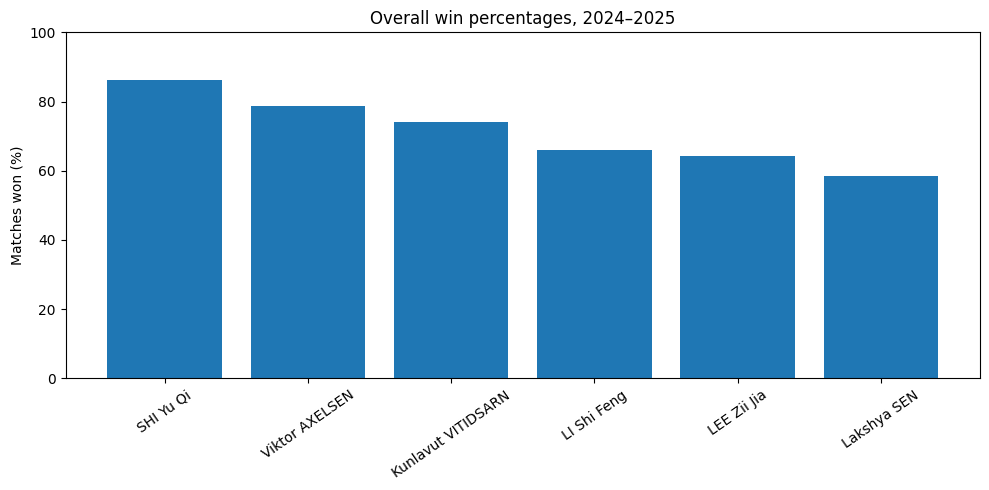

In [7]:
overall = (player_data.groupby("player")
           .agg(matches=("won", "size"), wins=("won", "sum")))
overall["losses"] = overall["matches"] - overall["wins"]
overall["win_pct"] = 100 * overall["wins"] / overall["matches"]
overall[["ci_low", "ci_high"]] = [
    wilson_interval(int(row.wins), int(row.matches)) for row in overall.itertuples()
]
overall = overall.sort_values("win_pct", ascending=False)
overall.round(1).to_csv(RESULT_DIR / "overall_summary.csv")
display(overall.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(overall.index, overall["win_pct"])
ax.set(ylabel="Matches won (%)", title="Overall win percentages, 2024–2025", ylim=(0, 100))
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(FIG_DIR / "overall_win_percentages.png", dpi=160)
plt.show()

## 8. Analysis B — Does performance vary between seasons?

Compare complete years 2024 and 2025. Differences are **percentage points**, not relative percentage changes.

,year,player,matches,wins,win_pct
0,2024,Kunlavut VITIDSARN,51,37,72.5
1,2024,LEE Zii Jia,49,34,69.4
2,2024,LI Shi Feng,41,26,63.4
3,2024,Lakshya SEN,36,22,61.1
4,2024,SHI Yu Qi,49,41,83.7
5,2024,Viktor AXELSEN,39,32,82.1
6,2025,Kunlavut VITIDSARN,57,43,75.4
7,2025,LEE Zii Jia,7,2,28.6
8,2025,LI Shi Feng,50,34,68.0
9,2025,Lakshya SEN,41,23,56.1


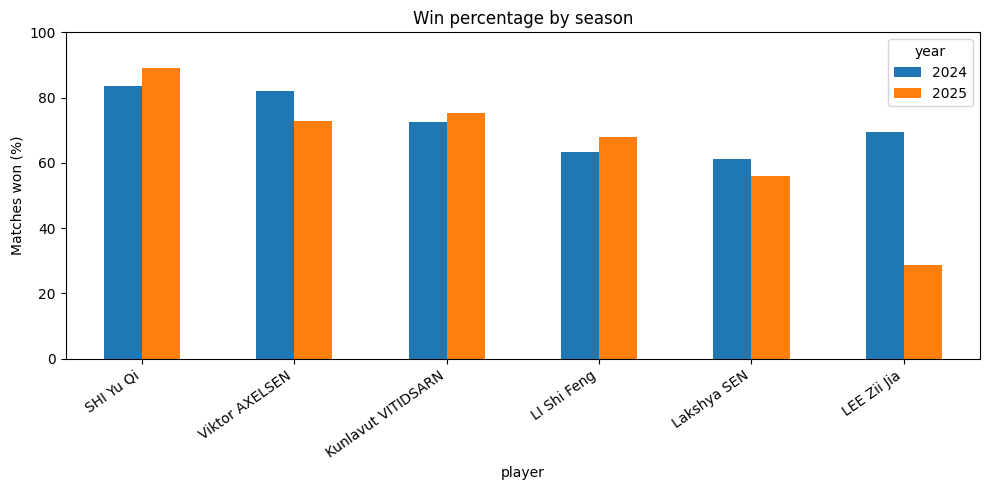

In [8]:
annual = (player_data.groupby(["year", "player"])
          .agg(matches=("won", "size"), wins=("won", "sum"))
          .reset_index())
annual["win_pct"] = 100 * annual["wins"] / annual["matches"]
annual.to_csv(RESULT_DIR / "annual_summary.csv", index=False)
display(annual.round(1))

pvt = annual.pivot(index="player", columns="year", values="win_pct").reindex(PLAYERS)
ax = pvt.plot(kind="bar", figsize=(10, 5))
ax.set(ylabel="Matches won (%)", title="Win percentage by season", ylim=(0, 100))
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "year_comparison.png", dpi=160)
plt.show()

## 9. Analysis C — First-game conversion

This question uses **only completed-score matches**. It measures a conditional proportion, not causation or predictive performance for a future match.

,game1_wins,match_wins,conversion_pct
player,,,
SHI Yu Qi,69,65,94.2
Viktor AXELSEN,42,39,92.9
Kunlavut VITIDSARN,70,66,94.3
LI Shi Feng,59,49,83.1
LEE Zii Jia,32,27,84.4
Lakshya SEN,43,36,83.7


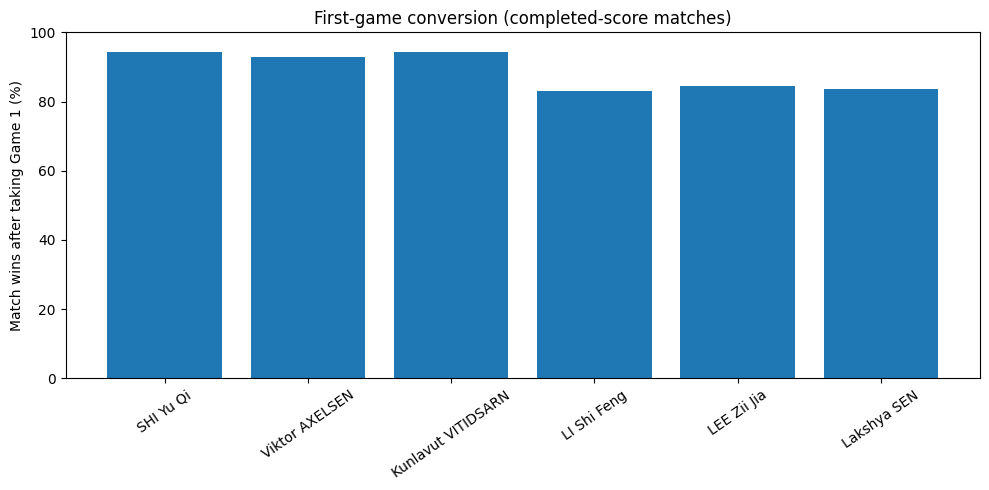

In [9]:
valid = player_data[player_data["valid_game_score"]].copy()
first_game = valid[valid["won_first_game"] == True].copy()
conversion = (first_game.groupby("player")
              .agg(game1_wins=("won", "size"), match_wins=("won", "sum")))
conversion["conversion_pct"] = 100 * conversion["match_wins"] / conversion["game1_wins"]
conversion = conversion.reindex(overall.index)
conversion.to_csv(RESULT_DIR / "first_game_conversion.csv")
display(conversion.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(conversion.index, conversion["conversion_pct"])
ax.set(ylabel="Match wins after taking Game 1 (%)", title="First-game conversion (completed-score matches)", ylim=(0, 100))
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(FIG_DIR / "first_game_conversion.png", dpi=160)
plt.show()

## 10. Analysis D — Three-game matches

A match is included here only if the validated scoreline shows **three completed games**. This is not a direct measure of a player's mental toughness or “clutch ability.”

,three_game_matches,three_game_wins,three_game_win_pct
player,,,
SHI Yu Qi,33,29,87.9
Viktor AXELSEN,25,17,68.0
Kunlavut VITIDSARN,36,26,72.2
LI Shi Feng,31,17,54.8
LEE Zii Jia,22,14,63.6
Lakshya SEN,31,17,54.8


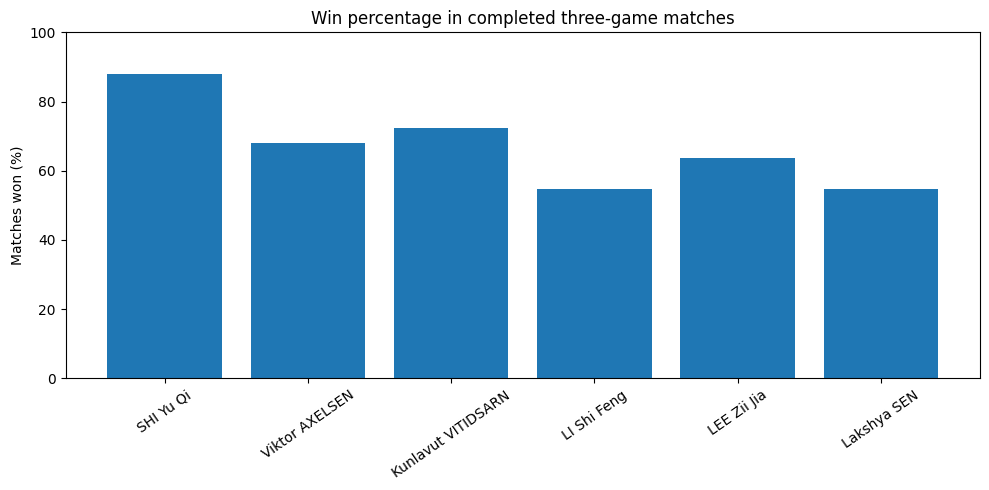

In [10]:
third = valid[valid["three_game_match"] == True].copy()
third_summary = (third.groupby("player")
                 .agg(three_game_matches=("won", "size"), three_game_wins=("won", "sum")))
third_summary["three_game_win_pct"] = (
    100 * third_summary["three_game_wins"] / third_summary["three_game_matches"]
)
third_summary = third_summary.reindex(overall.index)
third_summary.to_csv(RESULT_DIR / "three_game_summary.csv")
display(third_summary.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(third_summary.index, third_summary["three_game_win_pct"])
ax.set(ylabel="Matches won (%)", title="Win percentage in completed three-game matches", ylim=(0, 100))
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(FIG_DIR / "three_game_performance.png", dpi=160)
plt.show()

## 11. Quality checks and final findings

An important check: a player's number of wins plus losses must equal their matches played. Also compare the sizes of the full and completed-score samples. The report below pulls values directly from the tables. There are **no prewritten numerical findings**.

In [11]:
assert (overall["wins"] + overall["losses"] == overall["matches"]).all()
assert (conversion["match_wins"].dropna() <= conversion["game1_wins"].dropna()).all()
assert (third_summary["three_game_wins"].dropna() <= third_summary["three_game_matches"].dropna()).all()
assert len(valid) <= len(player_data)
print("Match-level observations:", len(matches))
print("Player-level observations:", len(player_data))
print("Completed-score player observations:", len(valid))

leader = overall.iloc[0]
leader_name = overall.index[0]
full_report = [
    "# Results and Interpretation",
    "",
    "## Study scope",
    f"This analysis examines {len(matches)} main-draw match records involving at least one of six selected men's singles players in 2024–2025.",
    f"Those records produce {len(player_data)} player-match observations. {len(valid)} player-match observations have validated completed scorelines for game-level analyses.",
    "",
    "## Findings",
    f"1. **Overall results:** {leader_name} had the highest observed win percentage within this selected group: {leader.win_pct:.1f}% ({int(leader.wins)} wins in {int(leader.matches)} matches).",
]
annual_wide = annual.pivot(index="player", columns="year", values="win_pct").dropna()
if 2024 in annual_wide and 2025 in annual_wide and not annual_wide.empty:
    differences = annual_wide[2025] - annual_wide[2024]
    name = differences.abs().idxmax()
    full_report.append(f"2. **Season comparison:** {name} had the largest absolute 2024-to-2025 difference, {differences.loc[name]:+.1f} percentage points.")
if conversion["game1_wins"].sum() > 0:
    total = int(conversion["game1_wins"].sum())
    wins = int(conversion["match_wins"].sum())
    full_report.append(f"3. **First-game conversion:** {wins} of {total} player-match observations where Game 1 was won ended in a match win ({percent(wins, total):.1f}%). This calculation includes completed-score records only.")
if third_summary["three_game_matches"].sum() > 0:
    total = int(third_summary["three_game_matches"].sum())
    wins = int(third_summary["three_game_wins"].sum())
    full_report.append(f"4. **Three-game results:** The six-player sample records {wins} wins among {total} player-match observations involving completed three-game matches ({percent(wins, total):.1f}%).")
full_report += [
    "", "## Interpretation",
    "These differences describe the recorded matches, not innate player ability. Match schedules, opponents, and sample sizes differ across players. LEE Zii Jia had only seven eligible matches in 2025, making his season comparison especially unstable. A successful first game is part of the scoring process itself, so its association with the final result should not be presented as causal.",
    "", "## Limitations",
    "- Only six chosen players and two calendar years are examined; selection was not random.",
    "- The dataset is a third-party compilation of public BWF results, not independently audited by this project.",
    "- Opponent strength and tournament selection are not adjusted for.",
    "- Game-level results exclude incomplete or inconsistent scorelines; this could affect comparisons.",
    "- Different matches are not necessarily statistically independent; 95% Wilson intervals are approximate descriptors, not formal evidence of differences.",
    "- LEE Zii Jia has only seven recorded eligible matches in 2025; the large year-to-year change is especially sensitive to this small sample.",
    "- Observational percentages do not identify causal effects or predict future match outcomes.",
    "", "## Conclusion",
    "The study shows how basic programming and proportion-based statistics can answer concrete questions about professional badminton. The most important analytical lesson is that a percentage only becomes meaningful when its denominator, data exclusions, and limits are explained.",
    "", "## Source",
    "SahilMotyar, *bwf-match-data*: https://github.com/SahilMotyar/bwf-match-data",
]
report_text = "\n".join(full_report)
(RESULT_DIR / "FINAL_REPORT.md").write_text(report_text, encoding="utf-8")
display(Markdown(report_text))
print("Saved results/FINAL_REPORT.md")

Match-level observations: 454
Player-level observations: 488
Completed-score player observations: 475


# Results and Interpretation

## Study scope
This analysis examines 454 main-draw match records involving at least one of six selected men's singles players in 2024–2025.
Those records produce 488 player-match observations. 475 player-match observations have validated completed scorelines for game-level analyses.

## Findings
1. **Overall results:** SHI Yu Qi had the highest observed win percentage within this selected group: 86.3% (82 wins in 95 matches).
2. **Season comparison:** LEE Zii Jia had the largest absolute 2024-to-2025 difference, -40.8 percentage points.
3. **First-game conversion:** 282 of 315 player-match observations where Game 1 was won ended in a match win (89.5%). This calculation includes completed-score records only.
4. **Three-game results:** The six-player sample records 120 wins among 178 player-match observations involving completed three-game matches (67.4%).

## Interpretation
These differences describe the recorded matches, not innate player ability. Match schedules, opponents, and sample sizes differ across players. LEE Zii Jia had only seven eligible matches in 2025, making his season comparison especially unstable. A successful first game is part of the scoring process itself, so its association with the final result should not be presented as causal.

## Limitations
- Only six chosen players and two calendar years are examined; selection was not random.
- The dataset is a third-party compilation of public BWF results, not independently audited by this project.
- Opponent strength and tournament selection are not adjusted for.
- Game-level results exclude incomplete or inconsistent scorelines; this could affect comparisons.
- Different matches are not necessarily statistically independent; 95% Wilson intervals are approximate descriptors, not formal evidence of differences.
- LEE Zii Jia has only seven recorded eligible matches in 2025; the large year-to-year change is especially sensitive to this small sample.
- Observational percentages do not identify causal effects or predict future match outcomes.

## Conclusion
The study shows how basic programming and proportion-based statistics can answer concrete questions about professional badminton. The most important analytical lesson is that a percentage only becomes meaningful when its denominator, data exclusions, and limits are explained.

## Source
SahilMotyar, *bwf-match-data*: https://github.com/SahilMotyar/bwf-match-data

Saved results/FINAL_REPORT.md


## 12. What I would study next

This version intentionally uses elementary Python and proportions rather than machine learning. A meaningful extension would add **opponent rankings measured at match time** and ask whether player differences persist after adjusting for opponent strength. Another extension would estimate uncertainty more carefully using resampling grouped by tournament.

### A short explanation of the statistical value

The project practices *defining a sample, choosing denominators, validating records, estimating proportions, comparing complete seasons, and describing uncertainty*. These are all directly relevant to an introductory Statistics or Applied Mathematics course.